In [ ]:
!pip install -q medmnist pennylane torch torchvision scikit-learn matplotlib seaborn

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torchvision import models, transforms

import pennylane as qml

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
    )
import medmnist
from medmnist import INFO

In [ ]:
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("PennyLane version:", qml.__version__)
print("MedMNIST version:", medmnist.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu
PennyLane version: 0.45.1
MedMNIST version: 3.0.2
Device: cpu


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [ ]:
from medmnist import PneumoniaMNIST

print(INFO["pneumoniamnist"])

{'python_class': 'PneumoniaMNIST', 'description': 'The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray images. The task is binary-class classification of pneumonia against normal. We split the source training set with a ratio of 9:1 into training and validation set and use its source validation set as the test set. The source images are gray-scale, and their sizes are (384−2,916)×(127−2,713). We center-crop the images and resize them into 1×28×28.', 'url': 'https://zenodo.org/records/10519652/files/pneumoniamnist.npz?download=1', 'MD5': '28209eda62fecd6e6a2d98b1501bb15f', 'url_64': 'https://zenodo.org/records/10519652/files/pneumoniamnist_64.npz?download=1', 'MD5_64': '8f4eceb4ccffa70c672198ea285246c6', 'url_128': 'https://zenodo.org/records/10519652/files/pneumoniamnist_128.npz?download=1', 'MD5_128': '05b46931834c231683c68f40c47b2971', 'url_224': 'https://zenodo.org/records/10519652/files/pneumoniamnist_224.npz?download=1', 'MD5_224': 'd6a3c71de1b945ea11211b

In [ ]:
transform = transforms.Compose([
      transforms.Resize((224, 224)),
      transforms.Grayscale(num_output_channels=3),
      transforms.ToTensor(),
      transforms.Normalize(
          mean=[0.485, 0.456, 0.406],
          std=[0.229, 0.224, 0.225]
          )
      ])


In [ ]:
train_dataset = PneumoniaMNIST(
      split="train",
      transform=transform,
      download=True
)

val_dataset = PneumoniaMNIST(
    split="val",
    transform=transform,
    download=True
)

test_dataset = PneumoniaMNIST(
    split="test",
    transform=transform,
    download=True
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))


Training samples: 4708
Validation samples: 524
Testing samples: 624


In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(
train_dataset,
batch_size=BATCH_SIZE,
shuffle=True,
num_workers=2,
pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created.")

DataLoaders created.


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


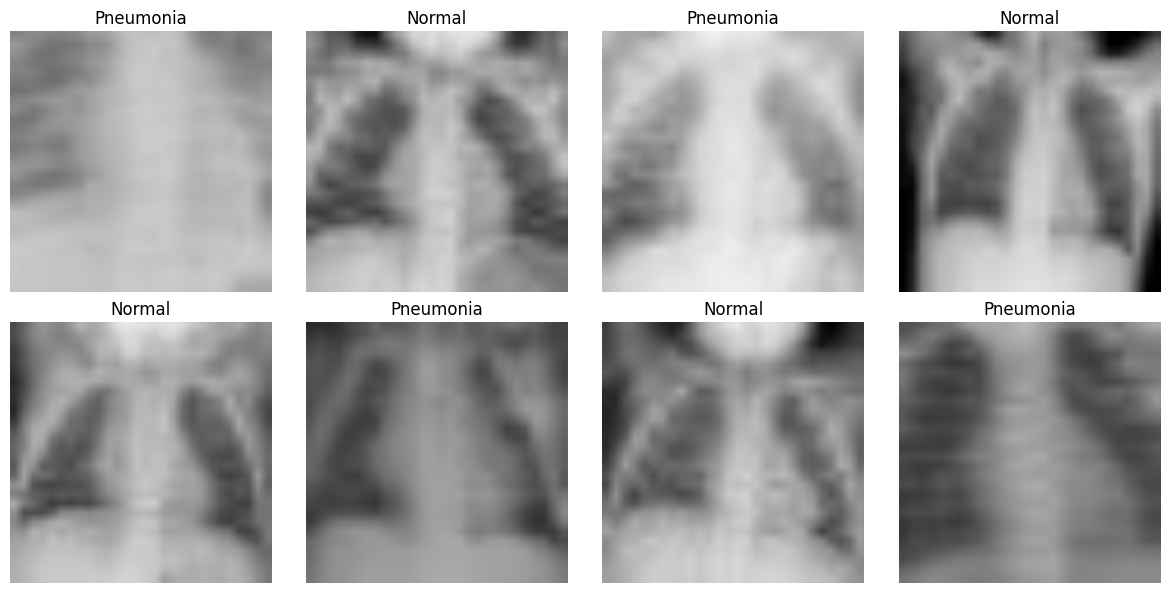

In [ ]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    img = images[i].permute(1, 2, 0).numpy()

        # Undo normalization approximately
    img = img * np.array([0.229, 0.224, 0.225])
    img = img + np.array([0.485, 0.456, 0.406])
    img = np.clip(img, 0, 1)

    ax.imshow(img)
    ax.set_title(
        "Pneumonia" if labels[i].item() == 1 else "Normal"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
weights = models.ResNet18_Weights.DEFAULT

resnet = models.resnet18(weights=weights)

print(resnet)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
for param in resnet.parameters():
      param.requires_grad = False

print("All ResNet18 parameters are frozen.")

All ResNet18 parameters are frozen.


In [ ]:
resnet.fc = nn.Identity()

resnet = resnet.to(device)

print(resnet)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
N_QUBITS = 4
N_Q_LAYERS = 2

dev = qml.device(
    "default.qubit",
    wires=N_QUBITS
)

print(dev)

<default.qubit device (wires=4) at 0x7885e4e4e7b0>


In [ ]:
@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):

    # Encode classical features into quantum rotations
        for i in range(N_QUBITS):
          qml.RY(inputs[...,i], wires=i)

                    # Variational quantum layers
        for layer in range(N_Q_LAYERS):
          for i in range(N_QUBITS):
            qml.RY(weights[layer, i, 0], wires=i)
            qml.RZ(weights[layer, i, 1], wires=i)

          for i in range(N_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])


            qml.CNOT(wires=[N_QUBITS - 1, 0])

        return [
            qml.expval(qml.PauliZ(i))
            for i in range(N_QUBITS)
        ]

In [ ]:
test_input = torch.tensor(
      [0.1, 0.2, 0.3, 0.4],
      dtype=torch.float32
      )

test_weights = torch.randn(
    N_Q_LAYERS,
    N_QUBITS,
    2,
    requires_grad=True
)
output = quantum_circuit(test_input, test_weights)

print("Quantum output:")
print(output)


Quantum output:
[tensor(0.2766, dtype=torch.float64, grad_fn=<DotBackward0>), tensor(0.7122, dtype=torch.float64, grad_fn=<DotBackward0>), tensor(0.5207, dtype=torch.float64, grad_fn=<DotBackward0>), tensor(0.3982, dtype=torch.float64, grad_fn=<DotBackward0>)]


In [ ]:
weight_shapes = {
      "weights": (N_Q_LAYERS, N_QUBITS, 2)
      }

qlayer = qml.qnn.TorchLayer(
    quantum_circuit,
    weight_shapes
)

print(qlayer)


<Quantum Torch Layer: func=quantum_circuit>


In [ ]:
class QuantumTransferModel(nn.Module):

      def __init__(self):
        super().__init__()

        self.feature_extractor = resnet

        self.feature_reducer = nn.Sequential(
            nn.Linear(512, 4),
            nn.Tanh()
        )

        self.quantum_layer = qlayer


        self.classifier = nn.Linear(4, 2)

      def forward(self, x):
        self.feature_extractor.eval()

        with torch.no_grad():
          features = self.feature_extractor(x)


        reduced_features = self.feature_reducer(features)

        quantum_output = self.quantum_layer(reduced_features)

        if isinstance(quantum_output, list):
          quantum_output = torch.stack(quantum_output, dim=1)


        output = self.classifier(quantum_output)

        return output



In [ ]:
model = QuantumTransferModel()

model = model.to(device)

print(model)

QuantumTransferModel(
  (feature_extractor): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1,

In [ ]:
total_params = sum(
      p.numel()
      for p in model.parameters()
       )

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)


Total parameters: 11178590
Trainable parameters: 2078


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=0.001
)

print("Optimizer:", optimizer)

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):

      model.train()

      running_loss = 0.0
      correct = 0
      total = 0

      for images, labels in loader:
        images = images.to(device)

        labels = labels.view(-1).long().to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

      epoch_loss = running_loss / total

      epoch_accuracy = correct / total

      return epoch_loss, epoch_accuracy

In [ ]:
def evaluate(model, loader, criterion):

      model.eval()

      running_loss = 0.0
      correct = 0
      total = 0

      all_labels = []
      all_predictions = []

      with torch.no_grad():
        for images, labels in loader:
          images = images.to(device)

          labels = labels.view(-1).long().to(device)
          outputs = model(images)

          loss = criterion(
              outputs,
              labels
          )
          running_loss += (
              loss.item() * images.size(0)
          )
          _, predicted = torch.max(
              outputs,
              1
          )
          total += labels.size(0)
          correct += (
              predicted == labels
          ).sum().item()

          all_labels.extend(
              labels.cpu().numpy()
          )

          all_predictions.extend(
              predicted.cpu().numpy()
         )


      epoch_loss = running_loss / total

      epoch_accuracy = correct / total

      return (
          epoch_loss,
          epoch_accuracy,
          all_labels,
          all_predictions
      )










In [ ]:
EPOCHS = 5

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):

  train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

  val_loss, val_acc, _, _ = evaluate(
        model,
        val_loader,
        criterion
    )

  train_losses.append(train_loss)
  train_accuracies.append(train_acc)

  val_losses.append(val_loss)
  val_accuracies.append(val_acc)

  print(
      f"Epoch [{epoch+1}/{EPOCHS}] "
      f"Train Loss: {train_loss:.4f} "
      f"Train Acc: {train_acc:.4f} "
      f"Val Loss: {val_loss:.4f} "
      f"Val Acc: {val_acc:.4f}"
   )



Epoch [1/5] Train Loss: 0.5961 Train Acc: 0.7732 Val Loss: 0.4895 Val Acc: 0.8760
Epoch [2/5] Train Loss: 0.4005 Train Acc: 0.9138 Val Loss: 0.3521 Val Acc: 0.9141
Epoch [3/5] Train Loss: 0.2825 Train Acc: 0.9420 Val Loss: 0.2655 Val Acc: 0.9389
Epoch [4/5] Train Loss: 0.2117 Train Acc: 0.9494 Val Loss: 0.2080 Val Acc: 0.9389
Epoch [5/5] Train Loss: 0.1756 Train Acc: 0.9486 Val Loss: 0.1746 Val Acc: 0.9523


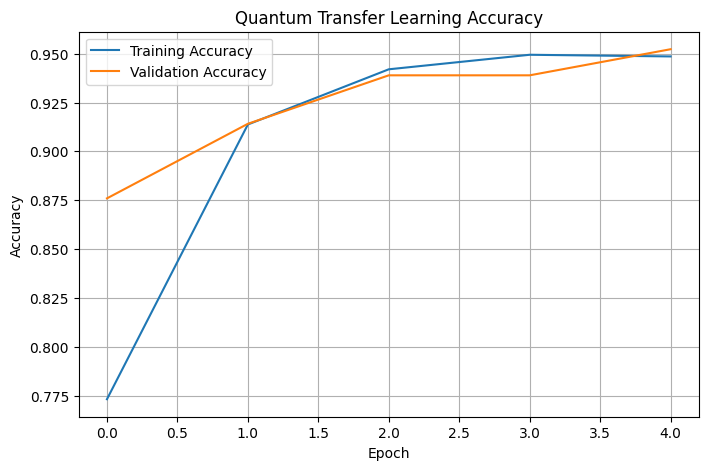

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Quantum Transfer Learning Accuracy"
)

plt.legend()
plt.grid()

plt.show()

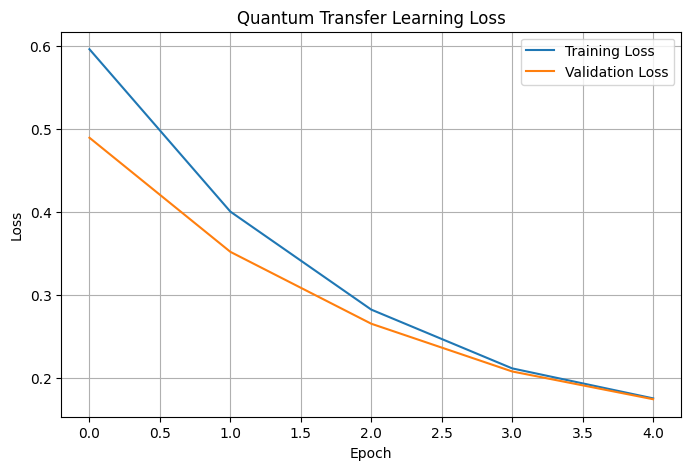

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Quantum Transfer Learning Loss"
)

plt.legend()
plt.grid()

plt.show()

In [ ]:
print(train_accuracies)
print(val_accuracies)

[0.7731520815632965, 0.9137638062871708, 0.9420135938827527, 0.949447748513169, 0.9485981308411215]
[0.8759541984732825, 0.9141221374045801, 0.9389312977099237, 0.9389312977099237, 0.9522900763358778]


In [ ]:
print(len(train_accuracies))
print(len(val_accuracies))

5
5


In [ ]:
test_loss, test_accuracy, y_true, y_pred = evaluate(
    model,
    test_loader,
    criterion
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


Test Loss: 0.3729153649929242
Test Accuracy: 0.8589743589743589


In [ ]:
accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)


Accuracy : 0.8589743589743589
Precision: 0.8240343347639485
Recall   : 0.9846153846153847
F1 Score : 0.897196261682243


In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Normal",
            "Pneumonia"
        ],
        zero_division=0
      )
  )


              precision    recall  f1-score   support

      Normal       0.96      0.65      0.78       234
   Pneumonia       0.82      0.98      0.90       390

    accuracy                           0.86       624
   macro avg       0.89      0.82      0.84       624
weighted avg       0.88      0.86      0.85       624



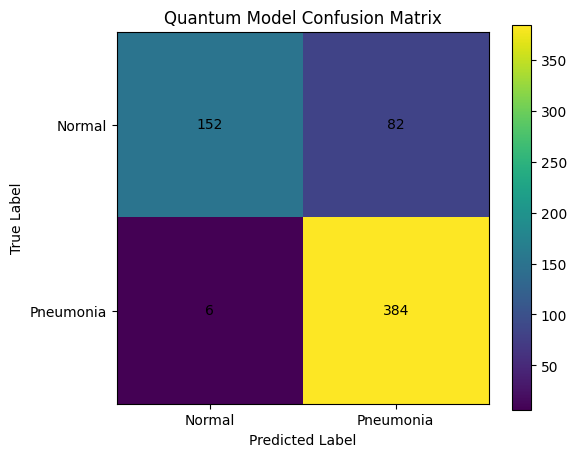

In [ ]:
cm = confusion_matrix(
      y_true,
      y_pred
)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title(
    "Quantum Model Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    [0, 1],
    ["Normal", "Pneumonia"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Pneumonia"]
)

for i in range(2):
  for j in range(2):
    plt.text(
        j,
        i,
        cm[i, j],
        ha="center",
        va="center"
    )

plt.colorbar()

plt.show()


In [ ]:
model.eval()

image, label = test_dataset[0]

input_image = image.unsqueeze(0).to(device)

with torch.no_grad():

    output = model(input_image)

    probabilities = torch.softmax(
        output,
        dim=1
    )

    prediction = torch.argmax(
        probabilities,
        dim=1
    ).item()

true_label = int(label)

class_names = [
    "Normal",
    "Pneumonia"
]

print(
    "Actual:",
    class_names[true_label]
)

print(
    "Predicted:",
    class_names[prediction]
)

print(
    "Confidence:",
    probabilities[0][prediction].item()
)

Actual: Pneumonia
Predicted: Pneumonia
Confidence: 0.9545575976371765


/tmp/ipykernel_40629/553503570.py:21: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  true_label = int(label)


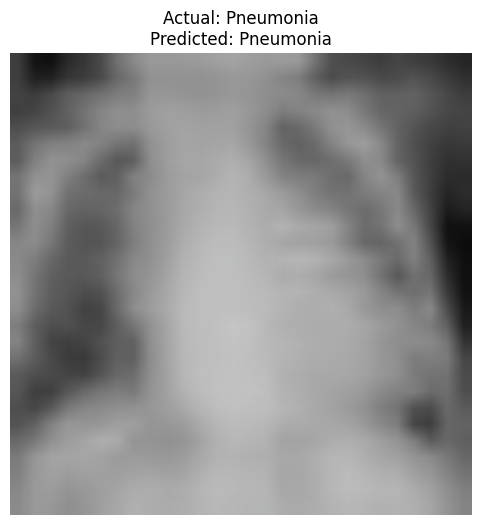

In [ ]:
img = image.permute(1, 2, 0).numpy()

img = img * np.array(
    [0.229, 0.224, 0.225]
)

img = img + np.array(
    [0.485, 0.456, 0.406]
)

img = np.clip(img, 0, 1)

plt.figure(figsize=(6, 6))

plt.imshow(img)

plt.title(
    f"Actual: {class_names[true_label]}\n"
    f"Predicted: {class_names[prediction]}"
)

plt.axis("off")

plt.show()

In [ ]:
torch.save(
    model.state_dict(),
    "quantum_transfer_pneumonia_model.pth"
)

print("Model saved successfully.")


Model saved successfully.


In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models

class ClassicalTransferModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.feature_extractor = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )

        for param in self.feature_extractor.parameters():
            param.requires_grad = False

        self.feature_extractor.fc = nn.Identity()

        self.feature_reducer = nn.Linear(512, 4)

        self.classifier = nn.Linear(4, 2)

    def forward(self, x):
        self.feature_extractor.eval()

        with torch.no_grad():
            features = self.feature_extractor(x)

        reduced_features = self.feature_reducer(features)

        output = self.classifier(reduced_features)

        return output

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

classical_model = ClassicalTransferModel().to(device)

classical_criterion = nn.CrossEntropyLoss()

classical_optimizer = torch.optim.Adam(
    [
        {"params": classical_model.feature_reducer.parameters()},
        {"params": classical_model.classifier.parameters()}
    ],
    lr=0.001
)

In [ ]:
CLASSICAL_EPOCHS = 5

# Create DataLoaders if they are not already available
from torch.utils.data import DataLoader

if 'train_loader' not in globals():
    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True
    )

if 'val_loader' not in globals():
    val_loader = DataLoader(
        val_dataset,
        batch_size=32,
        shuffle=False
    )

# Train classical model
for epoch in range(CLASSICAL_EPOCHS):

    classical_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device).long().view(-1)

        classical_optimizer.zero_grad()

        outputs = classical_model(images)
        loss = classical_criterion(outputs, labels)

        loss.backward()
        classical_optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation
    classical_model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device).long().view(-1)

            outputs = classical_model(images)
            loss = classical_criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch [{epoch+1}/{CLASSICAL_EPOCHS}] "
        f"Train Acc: {train_acc:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch [1/5] Train Acc: 0.8668 Val Acc: 0.9027
Epoch [2/5] Train Acc: 0.9282 Val Acc: 0.9218
Epoch [3/5] Train Acc: 0.9401 Val Acc: 0.9408
Epoch [4/5] Train Acc: 0.9490 Val Acc: 0.9466
Epoch [5/5] Train Acc: 0.9518 Val Acc: 0.9542


In [ ]:
classical_test_loss, classical_test_accuracy, \
classical_y_true, classical_y_pred = evaluate(
    classical_model,
    test_loader,
    classical_criterion
)

classical_precision = precision_score(
    classical_y_true,
    classical_y_pred,
    zero_division=0
)

classical_recall = recall_score(
    classical_y_true,
    classical_y_pred,
    zero_division=0
)

classical_f1 = f1_score(
    classical_y_true,
    classical_y_pred,
    zero_division=0
)
print("Classical Model")
print("----------------")
print("Accuracy :", classical_test_accuracy)
print("Precision:", classical_precision)
print("Recall   :", classical_recall)
print("F1 Score :", classical_f1)

Classical Model
----------------
Accuracy : 0.8365384615384616
Precision: 0.7962962962962963
Recall   : 0.9923076923076923
F1 Score : 0.8835616438356164


In [ ]:
print("===================================")
print("      MODEL COMPARISON")
print("===================================")

print("\nClassical Transfer Learning")
print("Accuracy :", classical_test_accuracy)
print("Precision:", classical_precision)
print("Recall   :", classical_recall)
print("F1 Score :", classical_f1)

print("\nQuantum Transfer Learning")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

      MODEL COMPARISON

Classical Transfer Learning
Accuracy : 0.8365384615384616
Precision: 0.7962962962962963
Recall   : 0.9923076923076923
F1 Score : 0.8835616438356164

Quantum Transfer Learning
Accuracy : 0.8589743589743589
Precision: 0.8240343347639485
Recall   : 0.9846153846153847
F1 Score : 0.897196261682243


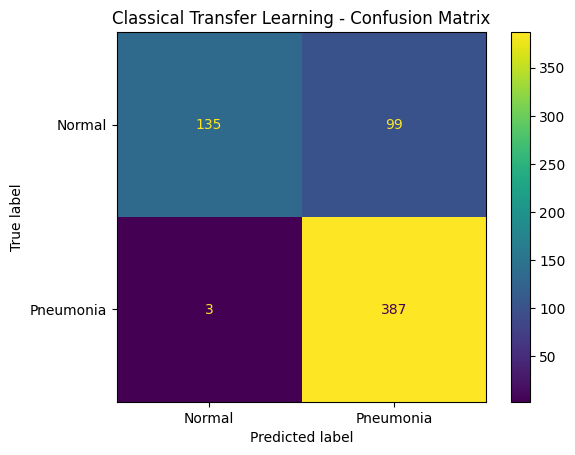

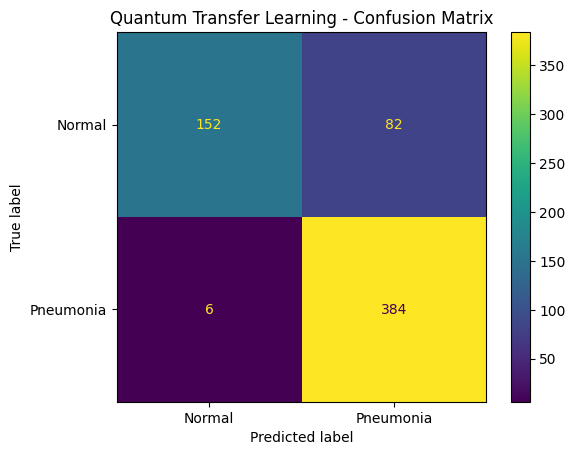

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def get_predictions(model, loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device).long().view(-1)

            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return all_labels, all_preds


# -------------------------------
# Classical Model
# -------------------------------
classical_labels, classical_preds = get_predictions(
    classical_model,
    test_loader
)


# -------------------------------
# Find Quantum Model
# -------------------------------
if 'quantum_model' in globals():
    q_model = quantum_model

elif 'quantum_transfer_model' in globals():
    q_model = quantum_transfer_model

elif 'model' in globals():
    q_model = model

else:
    raise NameError(
        "Quantum model variable was not found. "
        "Please send me the cell where you created/trained the quantum model."
    )


# -------------------------------
# Quantum Model
# -------------------------------
quantum_labels, quantum_preds = get_predictions(
    q_model,
    test_loader
)


# -------------------------------
# Classical Confusion Matrix
# -------------------------------
cm_classical = confusion_matrix(
    classical_labels,
    classical_preds
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_classical,
    display_labels=["Normal", "Pneumonia"]
)

disp.plot()
plt.title("Classical Transfer Learning - Confusion Matrix")
plt.show()


# -------------------------------
# Quantum Confusion Matrix
# -------------------------------
cm_quantum = confusion_matrix(
    quantum_labels,
    quantum_preds
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_quantum,
    display_labels=["Normal", "Pneumonia"]
)

disp.plot()
plt.title("Quantum Transfer Learning - Confusion Matrix")
plt.show()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


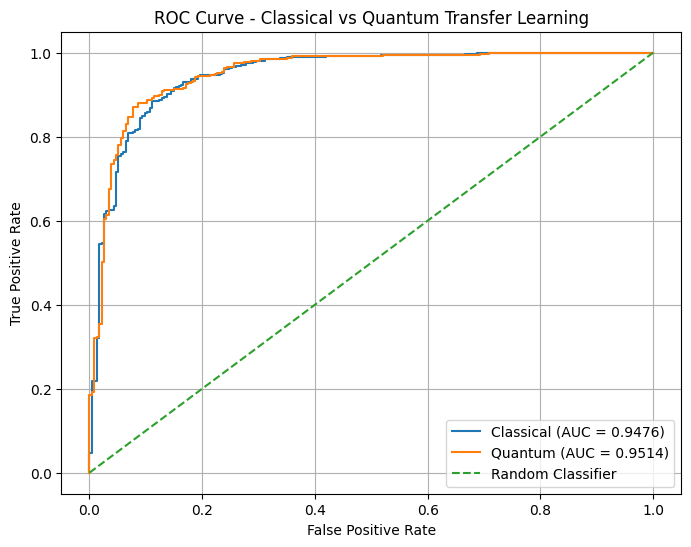

Classical ROC-AUC: 0.9476
Quantum ROC-AUC: 0.9514


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import torch

def get_probabilities(model, loader):
    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device).long().view(-1)

            outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)[:, 1]

            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probabilities.cpu().numpy())

    return all_labels, all_probs


# Classical
classical_roc_labels, classical_probs = get_probabilities(
    classical_model,
    test_loader
)

# Quantum
quantum_roc_labels, quantum_probs = get_probabilities(
    q_model,
    test_loader
)


# ROC curves
classical_fpr, classical_tpr, _ = roc_curve(
    classical_roc_labels,
    classical_probs
)

quantum_fpr, quantum_tpr, _ = roc_curve(
    quantum_roc_labels,
    quantum_probs
)


# AUC
classical_auc = roc_auc_score(
    classical_roc_labels,
    classical_probs
)

quantum_auc = roc_auc_score(
    quantum_roc_labels,
    quantum_probs
)


# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    classical_fpr,
    classical_tpr,
    label=f"Classical (AUC = {classical_auc:.4f})"
)

plt.plot(
    quantum_fpr,
    quantum_tpr,
    label=f"Quantum (AUC = {quantum_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Classical vs Quantum Transfer Learning")
plt.legend()
plt.grid()
plt.show()

print("Classical ROC-AUC:", round(classical_auc, 4))
print("Quantum ROC-AUC:", round(quantum_auc, 4))

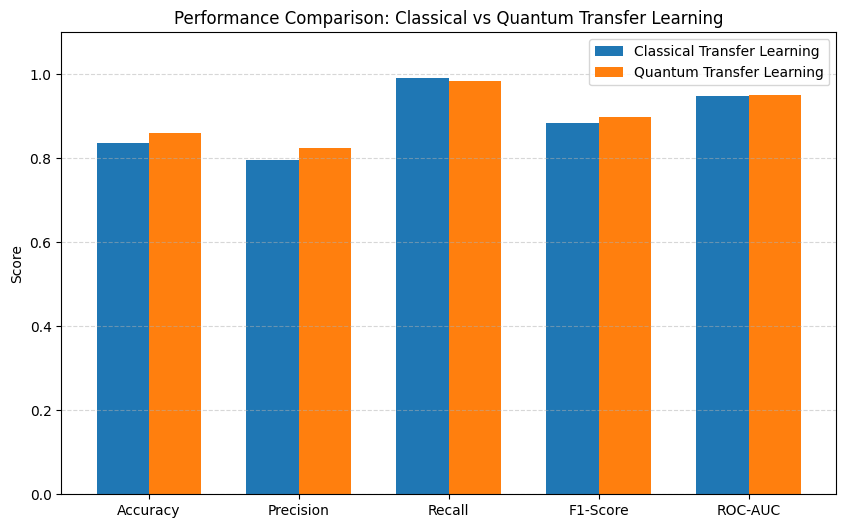

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Metric values
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

classical_values = [
    0.8365,
    0.7963,
    0.9923,
    0.8836,
    classical_auc
]

quantum_values = [
    0.8590,
    0.8240,
    0.9846,
    0.8972,
    quantum_auc
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    classical_values,
    width,
    label="Classical Transfer Learning"
)

plt.bar(
    x + width/2,
    quantum_values,
    width,
    label="Quantum Transfer Learning"
)

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.title("Performance Comparison: Classical vs Quantum Transfer Learning")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()